<a href="https://colab.research.google.com/github/iffathsaleem/RFM-Market-Analysis-Stock-Segmentation./blob/main/Market_Analysis_and_Stock_Segmentation_Using_RFM_CW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1 Data Preparation and Feature Engineering**

## 1.1 Ticker selection and data acquisition

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
start = '2021-01-01'
end = '2025-01-01'
benchmark_ticker = '^GSPC'

In [3]:
from pathlib import Path

In [4]:
from google.colab import drive
drive.mount('/content/drive')

project_folder = Path('/content/drive/MyDrive/Colab Notebooks/CRM Coursework 1')
output_folder = project_folder / 'CRM_CM_Enhanced_Results'
data_folder = output_folder / 'raw_data'
data_folder.mkdir(parents=True, exist_ok=True)
print('Save location:', output_folder)

Mounted at /content/drive
Save location: /content/drive/MyDrive/Colab Notebooks/CRM Coursework 1/CRM_CM_Enhanced_Results


In [5]:
USE_SAVED_DATA = (data_folder / 'SP500_Companies.csv').exists()

In [6]:
print('Reuse saved data:', USE_SAVED_DATA)

Reuse saved data: True


In [7]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
ticker_file = data_folder/ 'SP500_Companies.csv'

In [8]:
if ticker_file.exists():
    sp500_df = pd.read_csv(ticker_file)
    print('Using the saved constituent list. Check ticker_source.csv for its date.')
else:
    tables = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})
    sp500_df = tables[0]
    pass
    sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
    sp500_df.to_csv(ticker_file, index=False)

    ticker_source = pd.DataFrame([{
        'Source': url,
        'RetrievedUTC': pd.Timestamp.now(tz='UTC').isoformat(),
        'Start': start,
        'EndExclusive': end
    }])
    ticker_source.to_csv(data_folder / 'ticker_source.csv', index=False)

Using the saved constituent list. Check ticker_source.csv for its date.


In [9]:
tickers = sp500_df['Ticker'].tolist()
print('Total tickers:', len(tickers))
sp500_df[['Ticker', 'Security', 'GICS Sector']].head(10)

Total tickers: 503


,Ticker,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [10]:
import time

In [11]:
def download_data(ticker):
    filename = ticker.replace('^', 'index_') + '.csv'
    saved_file = data_folder / filename

    if saved_file.exists():
        data = pd.read_csv(saved_file, index_col=0, parse_dates=True)
    else:
        if USE_SAVED_DATA:
            raise ValueError('No cached history; refer to original acquisition failures')
        data = pd.DataFrame()
        for attempt in range(3):
            try:
                data = yf.Ticker(ticker).history(
                    start=start, end=end, auto_adjust=False, actions=True
                )
                if not data.empty:
                    break
            except Exception as error:
                print(ticker, error)
            time.sleep(2)

        if data.empty:
            raise ValueError('Download failed after three attempts')

        data.index = pd.to_datetime(data.index).tz_localize(None).normalize()
        data.to_csv(saved_file)

        download_record = pd.DataFrame([{
            'Ticker': ticker,
            'RetrievedUTC': pd.Timestamp.now(tz='UTC').isoformat(),
            'Start': start,
            'EndExclusive': end,
            'AutoAdjust': False
        }])
        download_record.to_csv(
            data_folder / (ticker.replace('^', 'index_') + '_source.csv'),
            index=False
        )

    data.index = pd.to_datetime(data.index).tz_localize(None).normalize()
    return data.sort_index()

In [12]:
market_data = download_data(benchmark_ticker)
market_data.head()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2021-01-04,3764.610107,3769.989990,3662.709961,3700.649902,3700.649902,5015000000,0.0,0.0
2021-01-05,3698.020020,3737.830078,3695.070068,3726.860107,3726.860107,4591020000,0.0,0.0
2021-01-06,3712.199951,3783.040039,3705.340088,3748.139893,3748.139893,6064110000,0.0,0.0
2021-01-07,3764.709961,3811.550049,3764.709961,3803.790039,3803.790039,5099160000,0.0,0.0
2021-01-08,3815.050049,3826.689941,3783.600098,3824.679932,3824.679932,4773040000,0.0,0.0


In [13]:
downloaded_data = {}
download_errors = []


In [14]:
for position, ticker in enumerate(tickers, start=1):
    try:
        downloaded_data[ticker] = download_data(ticker)
    except Exception as error:
        download_errors.append({'Ticker': ticker, 'Reason': str(error)})

    if position % 25 == 0:
        print('Processed', position, 'of', len(tickers))

Processed 25 of 503
Processed 50 of 503
Processed 75 of 503
Processed 100 of 503
Processed 125 of 503
Processed 150 of 503
Processed 175 of 503
Processed 200 of 503
Processed 225 of 503
Processed 250 of 503
Processed 275 of 503
Processed 300 of 503
Processed 325 of 503
Processed 350 of 503
Processed 375 of 503
Processed 400 of 503
Processed 425 of 503
Processed 450 of 503
Processed 475 of 503
Processed 500 of 503


In [15]:
pd.DataFrame(download_errors, columns=['Ticker', 'Reason']).to_csv(
    output_folder / 'download_errors.csv', index=False
)

In [16]:
print('Shares downloaded:', len(downloaded_data))
print('Acquisition failures:', len(download_errors))

Shares downloaded: 498
Acquisition failures: 5


## 1.2 Data Validation and Alignment

In [17]:
!pip install exchange_calendars

  Attempting uninstall: toolz
    Found existing installation: toolz 0.12.1
    Uninstalling toolz-0.12.1:
      Successfully uninstalled toolz-0.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [exchange_calendars]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.2.0 which is incompatible.


In [18]:
import exchange_calendars as xcals

In [19]:
calendar = xcals.get_calendar('XNYS')
trading_dates = pd.DatetimeIndex(
    calendar.sessions_in_range(start, '2024-12-31')
).tz_localize(None).normalize()

In [20]:
observation_date = trading_dates[-1]
print('Observation date:', observation_date.date())
print('Expected trading sessions:', len(trading_dates))

Observation date: 2024-12-31
Expected trading sessions: 1005


In [21]:
pass
pass
pass

In [22]:
market_data = market_data.reindex(trading_dates)
market_prices = market_data[['Close', 'Adj Close']]
pass
pass

In [23]:
shares_data = {}
validation_results = []

In [24]:
for ticker, data in downloaded_data.items():
    check = {'Ticker': ticker, 'Status': 'Excluded', 'Reason': ''}
    check['DuplicateDates'] = int(data.index.duplicated().sum())
    check['MissingSessions'] = int((~trading_dates.isin(data.index)).sum())
    check['UnexpectedDates'] = int((~data.index.isin(trading_dates)).sum())

    if check['DuplicateDates'] > 0:
        check['Reason'] = 'Duplicate dates'
    elif check['MissingSessions'] > 0:
        check['Reason'] = 'Incomplete study history'
    elif check['UnexpectedDates'] > 0:
        check['Reason'] = 'Unexpected non-session dates'
    elif not {'Close', 'Adj Close', 'Volume'}.issubset(data.columns):
        check['Reason'] = 'Missing required columns'
    else:
        data = data.reindex(trading_dates)
        check['MissingValues'] = int(data[['Close', 'Adj Close', 'Volume']].isna().sum().sum())
        check['BadPrices'] = int((data[['Close', 'Adj Close']] <= 0).sum().sum())
        check['NegativeVolume'] = int((data['Volume'] < 0).sum())
        check['ZeroVolume'] = int((data['Volume'] == 0).sum())
        check['FractionalVolume'] = int((data['Volume'].dropna() % 1 != 0).sum())
        finite = np.isfinite(data[['Close', 'Adj Close', 'Volume']].to_numpy()).all()

        if check['MissingValues'] > 0 or not finite:
            check['Reason'] = 'Missing or nonfinite values'
        elif check['BadPrices'] > 0:
            check['Reason'] = 'Nonpositive prices'
        elif check['NegativeVolume'] > 0 or check['ZeroVolume'] > 0 or check['FractionalVolume'] > 0:
            check['Reason'] = 'Volume requires investigation'
        else:
            shares_data[ticker] = data
            check['Status'] = 'Included'
            check['Reason'] = 'Passed automated checks; review corporate actions'

    validation_results.append(check)

In [25]:
validation_df = pd.DataFrame(validation_results)
validation_df.to_csv(output_folder / 'validation_log.csv', index=False)

In [26]:
print('Shares retained:', len(shares_data))
pass
validation_df.head(10)

Shares retained: 486


,Ticker,Status,Reason,DuplicateDates,MissingSessions,UnexpectedDates,MissingValues,BadPrices,NegativeVolume,ZeroVolume,FractionalVolume
0,MMM,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
1,AOS,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
2,ABT,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
3,ABBV,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
4,ACN,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
5,ADBE,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
6,AMD,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
7,AES,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
8,AFL,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0
9,A,Included,Passed automated checks; review corporate actions,0,0,0,0.0,0.0,0.0,0.0,0.0


In [27]:
action_results = []
adjustment_results = []

In [28]:
action_data = shares_data.copy()
action_data[benchmark_ticker] = market_data

In [29]:
for ticker, data in action_data.items():
    adjustment_ratio = data['Adj Close'] / data['Close']
    splits = data.get('Stock Splits', pd.Series(0, index=data.index)).fillna(0)
    dividends = data.get('Dividends', pd.Series(0, index=data.index)).fillna(0)

    adjustment_results.append({
        'Ticker': ticker,
        'CloseEqualsAdjClose': bool(np.allclose(data['Close'], data['Adj Close'], rtol=1e-7)),
        'MinimumAdjustmentRatio': adjustment_ratio.min(),
        'MaximumAdjustmentRatio': adjustment_ratio.max(),
        'SplitEvents': int((splits != 0).sum()),
        'DividendEvents': int((dividends != 0).sum()),
        'ReviewStatus': 'Manual review required'
    })

    flagged = (splits != 0) | (dividends != 0) | (adjustment_ratio.pct_change(fill_method=None).abs() > 0.01)
    for date in data.index[flagged]:
        action_results.append({
            'Ticker': ticker, 'Date': date,
            'Close': data.loc[date, 'Close'],
            'AdjClose': data.loc[date, 'Adj Close'],
            'Volume': data.loc[date, 'Volume'],
            'Split': splits.loc[date], 'Dividend': dividends.loc[date]
        })

In [30]:
adjustment_df = pd.DataFrame(adjustment_results)
action_df = pd.DataFrame(action_results, columns=['Ticker', 'Date', 'Close', 'AdjClose', 'Volume', 'Split', 'Dividend'])
adjustment_df.to_csv(output_folder / 'price_adjustment_checks.csv', index=False)
action_df.to_csv(output_folder / 'corporate_actions.csv', index=False)
adjustment_df.head(10)

,Ticker,CloseEqualsAdjClose,MinimumAdjustmentRatio,MaximumAdjustmentRatio,SplitEvents,DividendEvents,ReviewStatus
0,MMM,False,0.816725,0.963768,1,16,Manual review required
1,AOS,False,0.893317,0.957896,0,16,Manual review required
2,ABT,False,0.891483,0.957603,0,16,Manual review required
3,ABBV,False,0.798967,0.938138,0,16,Manual review required
4,ACN,False,0.904739,0.958330,0,16,Manual review required
5,ADBE,True,1.000000,1.000000,0,0,Manual review required
6,AMD,True,1.000000,1.000000,0,0,Manual review required
7,AES,False,0.793038,0.898242,0,16,Manual review required
8,AFL,False,0.872338,0.958865,0,16,Manual review required
9,A,False,0.960967,0.986385,0,17,Manual review required


In [31]:
split_checks = []
for ticker, data in shares_data.items():
    splits = data.get('Stock Splits', pd.Series(0, index=data.index)).fillna(0)
    for date in data.index[splits != 0]:
        location = data.index.get_loc(date)
        if location == 0:
            continue
        previous = data.iloc[location - 1]
        current = data.loc[date]
        split_checks.append({
            'Ticker': ticker, 'Date': date, 'SplitRatio': splits.loc[date],
            'CloseRatioToPreviousSession': current['Close'] / previous['Close'],
            'VolumeRatioToPreviousSession': current['Volume'] / previous['Volume'],
            'AdjustmentRatioBefore': previous['Adj Close'] / previous['Close'],
            'AdjustmentRatioAfter': current['Adj Close'] / current['Close'],
            'Interpretation': 'Diagnostic evidence only; vendor price-volume compatibility remains an assumption'
        })

In [32]:
split_checks_df = pd.DataFrame(split_checks)
split_checks_df.to_csv(output_folder / 'split_date_diagnostics.csv', index=False)
print('Recorded splits inspected:', len(split_checks_df))
split_checks_df.head(10)

Recorded splits inspected: 61


,Ticker,Date,SplitRatio,CloseRatioToPreviousSession,VolumeRatioToPreviousSession,AdjustmentRatioBefore,AdjustmentRatioAfter,Interpretation
0,MMM,2024-04-01,1.196,1.060129,2.479099,0.946953,0.946953,Diagnostic evidence only; vendor price-volume ...
1,GOOGL,2022-07-18,20.000,0.975420,0.922912,0.990574,0.990574,Diagnostic evidence only; vendor price-volume ...
2,GOOG,2022-07-18,20.000,0.974665,0.971570,0.990617,0.990617,Diagnostic evidence only; vendor price-volume ...
3,AMZN,2022-06-06,20.000,1.019943,1.385896,1.000000,1.000000,Diagnostic evidence only; vendor price-volume ...
4,APH,2021-03-05,2.000,1.025316,0.754762,0.950132,0.950132,Diagnostic evidence only; vendor price-volume ...
5,APH,2024-06-12,2.000,1.021945,1.387509,0.981087,0.981087,Diagnostic evidence only; vendor price-volume ...
6,ANET,2021-11-18,4.000,1.003558,1.289413,1.000000,1.000000,Diagnostic evidence only; vendor price-volume ...
7,ANET,2024-12-04,4.000,1.017517,0.814056,1.000000,1.000000,Diagnostic evidence only; vendor price-volume ...
8,T,2022-04-11,1.324,1.076641,2.153761,0.770526,0.770526,Diagnostic evidence only; vendor price-volume ...
9,BDX,2022-04-01,1.025,1.011513,1.128960,0.920416,0.920416,Diagnostic evidence only; vendor price-volume ...


In [33]:
df = pd.DataFrame({ticker: data['Adj Close'] for ticker, data in shares_data.items()})
print('Daily price table:', df.shape)
df.head()

Daily price table: (1005, 486)


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
2021-01-04,117.366669,48.167671,97.269714,84.219131,232.029358,485.339996,92.300003,18.430204,37.676277,114.009125,...,15.373580,188.764450,228.080002,102.852097,54.757378,93.015907,95.016197,378.130005,141.603424,152.952011
2021-01-05,117.168633,48.480335,98.473206,85.090012,233.350296,485.690002,92.769997,19.048773,37.737339,114.941254,...,15.840141,187.189117,225.360001,106.017517,54.223648,92.903923,95.025185,380.570007,144.053375,154.017899
2021-01-06,118.950958,50.150837,98.268158,84.354980,235.901642,466.309998,90.330002,19.810087,39.194149,118.093239,...,16.444378,188.764450,220.000000,106.652512,55.424545,96.822739,95.545944,394.820007,148.158371,156.280487
2021-01-07,115.898499,50.767239,99.222061,85.257790,238.127304,477.739990,95.160004,19.611828,38.976067,121.235603,...,16.474974,190.200821,226.210007,105.594185,54.340420,101.217415,94.818649,409.100006,147.280045,156.140259
2021-01-08,113.781555,50.168713,99.498413,85.705215,238.995895,485.100006,94.580002,20.159031,38.810322,122.100471,...,16.291401,188.708908,227.649994,104.901443,54.840782,100.191063,96.210388,405.470001,146.956512,157.178085


In [34]:
df1 = df.T
print('Transposed price table:', df1.shape)
df1.head()

Transposed price table: (486, 1005)


,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
MMM,117.366669,117.168633,118.950958,115.898499,113.781555,112.811867,113.706451,113.549385,113.638161,113.050903,...,123.410530,120.981834,122.523857,124.595955,124.306824,125.636826,126.427109,125.463341,124.451393,124.412834
AOS,48.167671,48.480335,50.150837,50.767239,50.168713,50.829765,52.509193,52.098282,51.294285,50.767239,...,67.828636,66.008636,65.558434,65.826645,65.673363,65.989479,65.989479,65.548843,65.156097,65.338104
ABT,97.269714,98.473206,98.268158,99.222061,99.498413,98.811974,97.028999,99.979805,98.493965,99.621773,...,108.486839,107.184509,107.653732,109.387001,109.463608,109.894531,110.382904,110.114777,108.017624,108.314484
ABBV,84.219131,85.090012,84.354980,85.257790,85.705215,87.103409,87.710640,89.843872,90.231857,89.334625,...,164.530701,162.316711,160.909470,164.718338,167.354507,168.864899,168.114395,166.997986,165.299973,166.707169
ACN,232.029358,233.350296,235.901642,238.127304,238.995895,235.548782,233.784531,233.385086,231.496765,230.271225,...,342.411194,333.124969,356.652008,351.103241,343.819946,346.560760,345.410767,341.337830,337.801636,337.130829


## 1.3 Weekly Return and Weekly Beta


In [35]:
weekly_prices = df.resample('W-FRI').last()
market_weekly_prices = market_data['Adj Close'].resample('W-FRI').last()

In [36]:
week_labels = weekly_prices.index
complete_week = (
    (week_labels - pd.Timedelta(days=6) >= pd.Timestamp(start)) &
    (week_labels < pd.Timestamp(end))
)

In [37]:
weekly_prices = weekly_prices.loc[complete_week]
market_weekly_prices = market_weekly_prices.reindex(weekly_prices.index)

In [38]:
weekly_returns = weekly_prices.pct_change(fill_method=None)
market_weekly_returns = market_weekly_prices.pct_change(fill_method=None)

In [39]:
weekly_returns.to_csv(output_folder / 'weekly_returns.csv')
market_weekly_returns.to_csv(output_folder / 'benchmark_weekly_returns.csv')

In [40]:
print('First complete week:', weekly_prices.index[0].date())
print('Last complete week:', weekly_prices.index[-1].date())
weekly_returns.head()

First complete week: 2021-01-08
Last complete week: 2024-12-27


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036506,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038962
2021-01-22,0.021081,0.016364,0.013837,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522
2021-01-29,0.039163,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175425,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609


### *1.3.1 Mean weekly return*

In [41]:
mean_weekly_returns = weekly_returns.mean().rename('MeanWeeklyReturn')
mean_weekly_returns.to_csv(output_folder / 'mean_weekly_returns.csv')
print('Usable weekly returns per share:')
print(weekly_returns.notna().sum().value_counts())
mean_weekly_returns.head(10)

Usable weekly returns per share:
207    486
Name: count, dtype: int64


,MeanWeeklyReturn
MMM,0.001142
AOS,0.001991
ABT,0.000971
ABBV,0.003749
ACN,0.002376
ADBE,0.000990
AMD,0.003624
AES,-0.001420
AFL,0.005004
A,0.001121


### *1.3.2 Weekly beta calculation*

In [42]:
return_results = []

In [43]:
for ticker in weekly_returns.columns:
    paired = pd.concat([
        weekly_returns[ticker].rename('Share'),
        market_weekly_returns.rename('Market')
    ], axis=1).replace([np.inf, -np.inf], np.nan).dropna()

    market_variance = paired['Market'].var(ddof=1)
    pass

    mean_return = mean_weekly_returns.loc[ticker]
    beta = paired['Share'].cov(paired['Market']) / market_variance

    slope = np.polyfit(paired['Market'], paired['Share'], 1)[0]
    pass

    return_results.append({
        'Ticker': ticker,
        'MeanWeeklyReturn': mean_return,
        'Beta': beta,
        'PairedWeeks': len(paired)
    })

In [44]:
return_df = pd.DataFrame(return_results).set_index('Ticker')
return_df.head(10)

,MeanWeeklyReturn,Beta,PairedWeeks
Ticker,,,
MMM,0.001142,0.869079,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425367,207
ACN,0.002376,1.143300,207
ADBE,0.000990,1.553525,207
AMD,0.003624,1.877622,207
AES,-0.001420,1.143912,207
AFL,0.005004,0.707197,207


## 1.4 Adapted RFM Calculations

In [45]:
event_details = {}

In [46]:
for ticker, data in shares_data.items():
    data = data.loc[:observation_date].copy()
    pass

    average_volume = data['Volume'].shift(1).rolling(20, min_periods=20).mean()
    data['Previous20Mean'] = average_volume
    data['Threshold'] = 2 * average_volume
    data['HighVolume'] = (data['Volume'] > data['Threshold']) & average_volume.notna()
    data['DailyTradedValue'] = data['Close'] * data['Volume']
    data['InFinal60'] = data.index.isin(data.tail(60).index)
    pass
    event_details[ticker] = data

In [47]:
high_volume_days = pd.DataFrame({
    ticker: data['HighVolume'] for ticker, data in event_details.items()
})
print('High-volume flags:', high_volume_days.shape)
high_volume_days.tail()

High-volume flags: (1005, 486)


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
2024-12-24,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-26,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-27,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-30,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-31,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### *1.4.1 Recency*


In [48]:
recency_results = []

In [49]:
for ticker in high_volume_days.columns:
    qualifying_dates = high_volume_days.index[high_volume_days[ticker]]

    if len(qualifying_dates) == 0:
        last_event = pd.NaT
        recency = np.nan
    else:
        last_event = qualifying_dates[-1]
        recency = (observation_date - last_event).days

    recency_results.append({
        'Ticker': ticker, 'Recency': recency, 'LastEvent': last_event
    })

In [50]:
recency_df = pd.DataFrame(recency_results).set_index('Ticker')
recency_df.head(10)

,Recency,LastEvent
Ticker,,
MMM,11,2024-12-20
AOS,11,2024-12-20
ABT,11,2024-12-20
ABBV,11,2024-12-20
ACN,11,2024-12-20
ADBE,18,2024-12-13
AMD,18,2024-12-13
AES,54,2024-11-07
AFL,11,2024-12-20


### *1.4.2 Frequency*

In [51]:
high_volume_60_days = high_volume_days.tail(60)
pass

In [52]:
frequency_df = high_volume_60_days.sum().astype(int).to_frame('Frequency')
frequency_df.head(10)

,Frequency
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
ADBE,3
AMD,4
AES,3
AFL,2
A,2


### *1.4.3 Monetary*


In [53]:
daily_traded_value = pd.DataFrame({
    ticker: data['DailyTradedValue'] for ticker, data in event_details.items()
})
traded_value_60_days = daily_traded_value.tail(60)
pass

In [54]:
monetary_df = traded_value_60_days.sum().to_frame('Monetary')
monetary_df.head(10)

,Monetary
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
ADBE,1.030403e+11
AMD,3.131659e+11
AES,1.119578e+10
AFL,1.328456e+10
A,1.400180e+10


### Combine R, F and M

In [55]:
rfm = recency_df.join(frequency_df).join(monetary_df)
rfm['ObservationDate'] = observation_date
rfm = rfm[['ObservationDate', 'Recency', 'Frequency', 'Monetary', 'LastEvent']]
rfm.to_csv(output_folder / 'rfm_features.csv')
rfm.head(10)

,ObservationDate,Recency,Frequency,Monetary,LastEvent
Ticker,,,,,
MMM,2024-12-31,11,4,2.599146e+10,2024-12-20
AOS,2024-12-31,11,2,4.748980e+09,2024-12-20
ABT,2024-12-31,11,1,3.523027e+10,2024-12-20
ABBV,2024-12-31,11,3,6.837054e+10,2024-12-20
ACN,2024-12-31,11,2,5.199430e+10,2024-12-20
ADBE,2024-12-31,18,3,1.030403e+11,2024-12-13
AMD,2024-12-31,18,4,3.131659e+11,2024-12-13
AES,2024-12-31,54,3,1.119578e+10,2024-11-07
AFL,2024-12-31,11,2,1.328456e+10,2024-12-20


## 1.5 Metric Interpretation and Supporting Evidence

In [56]:
company_details = sp500_df.set_index('Ticker')[['Security', 'GICS Sector']]
features = return_df.join(rfm).join(company_details)
feature_columns = ['MeanWeeklyReturn', 'Beta', 'Recency', 'Frequency', 'Monetary']

In [57]:
features.to_csv(output_folder / 'all_features.csv')
common = features.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_columns).sort_index().copy()

In [58]:
excluded_rfm = features.loc[~features.index.isin(common.index)].copy()
excluded_rfm['Reason'] = 'Missing/nonfinite feature; no-event Recency is not zero'
excluded_rfm.to_csv(output_folder / 'rfm_exclusions.csv')
common.to_csv(output_folder / 'common_features.csv')

In [59]:
pass
pass
pass
pass

In [60]:
print('Common shares:', len(common))
print('Paired weekly observations:', common['PairedWeeks'].unique())
common.head(10)

Common shares: 486
Paired weekly observations: [207]


,MeanWeeklyReturn,Beta,PairedWeeks,ObservationDate,Recency,Frequency,Monetary,LastEvent,Security,GICS Sector
Ticker,,,,,,,,,,
A,0.001121,1.074724,207,2024-12-31,11,2,1.400180e+10,2024-12-20,Agilent Technologies,Health Care
AAPL,0.003930,1.174836,207,2024-12-31,11,2,6.233034e+11,2024-12-20,Apple Inc.,Information Technology
ABBV,0.003749,0.425367,207,2024-12-31,11,3,6.837054e+10,2024-12-20,AbbVie,Health Care
ABNB,0.001475,1.472709,207,2024-12-31,11,3,3.652850e+10,2024-12-20,Airbnb,Consumer Discretionary
ABT,0.000971,0.583543,207,2024-12-31,11,1,3.523027e+10,2024-12-20,Abbott Laboratories,Health Care
ACGL,0.005289,0.586638,207,2024-12-31,11,4,1.196213e+10,2024-12-20,Arch Capital Group,Financials
ACN,0.002376,1.143300,207,2024-12-31,11,2,5.199430e+10,2024-12-20,Accenture,Information Technology
ADBE,0.000990,1.553525,207,2024-12-31,18,3,1.030403e+11,2024-12-13,Adobe Inc.,Information Technology
ADI,0.002610,1.131969,207,2024-12-31,36,1,3.849918e+10,2024-11-25,Analog Devices,Information Technology


In [61]:
example_share = 'AAPL' if 'AAPL' in common.index else common.index[0]
example = event_details[example_share]

In [62]:
print('Worked example:', example_share)
print(common.loc[example_share, ['Recency', 'Frequency', 'Monetary', 'LastEvent']])

Worked example: AAPL
Recency                       11
Frequency                      2
Monetary     623303377706.584229
LastEvent    2024-12-20 00:00:00
Name: AAPL, dtype: object


In [63]:
example.to_csv(output_folder / ('worked_example_' + example_share + '.csv'))
example[['Close', 'Volume', 'Previous20Mean', 'Threshold', 'HighVolume', 'DailyTradedValue', 'InFinal60']].tail(60)

,Close,Volume,Previous20Mean,Threshold,HighVolume,DailyTradedValue,InFinal60
2024-10-07,221.690002,39505400,61024170.0,122048340.0,False,8.757952e+09,True
2024-10-08,225.770004,31855700,59640440.0,119280880.0,False,7.192062e+09,True
2024-10-09,229.539993,33591100,58653675.0,117307350.0,False,7.710501e+09,True
2024-10-10,229.039993,28183500,58103875.0,116207750.0,False,6.455149e+09,True
2024-10-11,227.550003,31759200,57640270.0,115280540.0,False,7.226806e+09,True
2024-10-14,231.300003,39882100,57389900.0,114779800.0,False,9.224730e+09,True
2024-10-15,233.850006,64751400,56416135.0,112832270.0,False,1.514212e+10,True
2024-10-16,231.779999,34082200,57377740.0,114755480.0,False,7.899572e+09,True
2024-10-17,232.149994,32993800,56087105.0,112174210.0,False,7.659510e+09,True
2024-10-18,235.000000,46431500,54397730.0,108795460.0,False,1.091140e+10,True


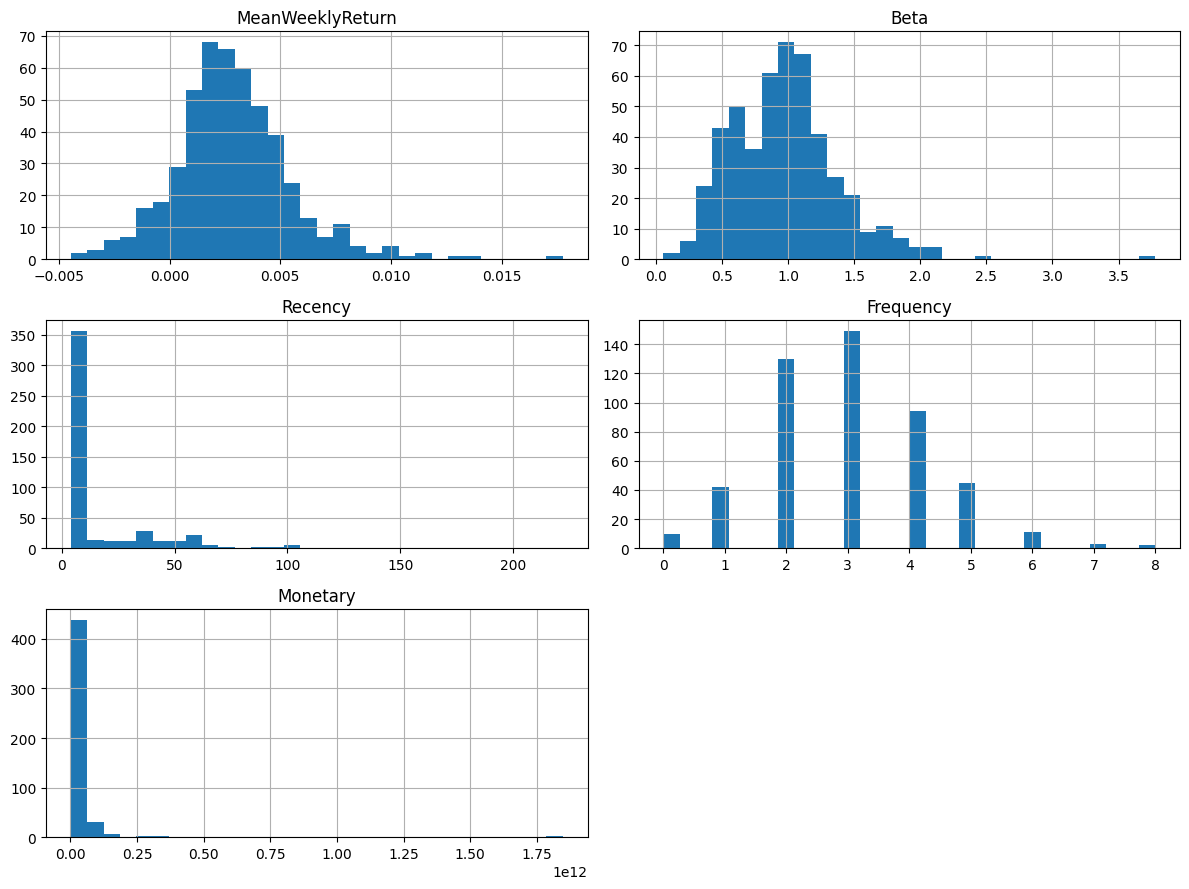

In [64]:
common[feature_columns].describe().to_csv(output_folder / 'feature_summary.csv')
common[feature_columns].hist(bins=30, figsize=(12, 9))
plt.tight_layout()
plt.savefig(output_folder / 'feature_distributions.png', dpi=160)
plt.show()

In [65]:
skewness = common[feature_columns].skew()
skewness.to_csv(output_folder / 'feature_skewness.csv')

In [66]:
outlier_results = []
for feature in feature_columns:
    q1, q3 = common[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    unusual = (common[feature] < q1 - 1.5 * iqr) | (common[feature] > q3 + 1.5 * iqr)
    for ticker in common.index[unusual]:
        outlier_results.append({'Ticker': ticker, 'Feature': feature, 'Value': common.loc[ticker, feature]})

In [67]:
pd.DataFrame(outlier_results, columns=['Ticker', 'Feature', 'Value']).to_csv(
    output_folder / 'outlier_review.csv', index=False
)
print(skewness)

MeanWeeklyReturn     0.867516
Beta                 1.103649
Recency              3.645784
Frequency            0.424735
Monetary            11.683797
dtype: float64
